# Analyze IMs potentially associated with the utilization of xylose and xylan deeply

In [ ]:
import os
from os import path
import pandas as pd

#plotting
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

#pymodulon
import pymodulon
from pymodulon.io import *
from pymodulon.plotting import *
from pymodulon.enrichment import compute_enrichment, compute_annotation_enrichment

In [2]:
# matplotlib default font
plt.rcParams['font.family'] = 'serif'
# Specify a preferred fallback list of fonts
plt.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif']

### LOAD THE DATA

In [ ]:
data_dir = path.join('..', 'ctherm_nf','processed_data')

# load the data
ica_data = load_json_model(path.join(data_dir, 'ctherm.json.gz')) #adjusted

# Other required information from icadata object
df_metadata = ica_data.sample_table
df_expression = ica_data.X


# ### gene info
df_gene_info = pd.read_csv(path.join(data_dir, 'gene_info.csv'), index_col=0)
df_gene_info.head()

/Users/skd6150/Applications/anaconda3/envs/modulome_mac/lib/python3.9/site-packages/pymodulon/util.py:31: FutureWarning: Passing literal json to 'read_json' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  table = pd.read_json(table)
/Users/skd6150/Applications/anaconda3/envs/modulome_mac/lib/python3.9/site-packages/pymodulon/util.py:31: FutureWarning: Passing literal json to 'read_json' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  table = pd.read_json(table)
/Users/skd6150/Applications/anaconda3/envs/modulome_mac/lib/python3.9/site-packages/pymodulon/util.py:31: FutureWarning: Passing literal json to 'read_json' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  table = pd.read_json(table)
/Users/skd6150/Applications/anaconda3/envs/modulome_mac/lib/python3.9/site-packages/p

,gene_name,accession,old_locus_tag,start,end,strand,gene_product,COG,uniprot,operon,GO_MF,GO_BP,InterPro,PFAMs
locus_tag,,,,,,,,,,,,,,
Clo1313_0001,dnaA,CP002416.1,NaN,212,1543,+,chromosomal replication initiator protein DnaA,No COG annotation,UPI0001B1F046,Op0,ATP binding; DNA replication origin binding; l...,DNA replication initiation; regulation of DNA ...,AAA+_ATPase;Chromosome_initiator_DnaA;Chromoso...,NaN
Clo1313_0002,RS00015,CP002416.1,NaN,1793,2893,+,DNA polymerase III%2C beta subunit,No COG annotation,UPI00017E1F7F,Op1,NaN,NaN,DNA_clamp_sf;DNA_polIII_beta;DNA_polIII_beta_C...,NaN
Clo1313_0003,yaaA,CP002416.1,NaN,2909,3115,+,S4 domain protein YaaA,No COG annotation,UPI000038F4E6,Op1,NaN,NaN,RNA-bd_S4-rel_YaaA;S4_RNA-bd;S4_RNA-bd_sf;,NaN
Clo1313_0004,recF,CP002416.1,NaN,3133,4242,+,DNA replication and repair protein RecF,No COG annotation,UPI00003C8C54,Op1,ATP binding; single-stranded DNA binding,DNA replication; DNA synthesis involved in DNA...,DNA-binding_RecF;DNA-binding_RecF_CS;P-loop_NT...,NaN
Clo1313_0005,RS00030,CP002416.1,NaN,4410,4724,+,hypothetical protein,Function unknown,UPI000038F4E8,Op2,NaN,NaN,RemA-like;,DUF370


### First rename the imodulon

In [4]:
df_rename_imod = pd.read_csv('./results_characterize_imodulons/imod_rename_mapping.tsv', sep='\t', index_col=0)
dict_rename_imod = df_rename_imod[['IM']].to_dict()['IM']

# rename all at once
ica_data.rename_imodulons(dict_rename_imod)

# set IM as index for this work
df_rename_imod.set_index('IM', inplace=True)

# GRN for regulation in C. thermocellum
for i,row in ica_data.imodulon_table.iterrows():
    if pd.notnull(row.regulator):
        ica_data.imodulon_table.loc[i, 'category'] = 'regulatory'
    else:
        ica_data.imodulon_table.loc[i, 'category'] = df_rename_imod.loc[i, 'category']



## Find pentose sugar associated IMs by performing DIMA

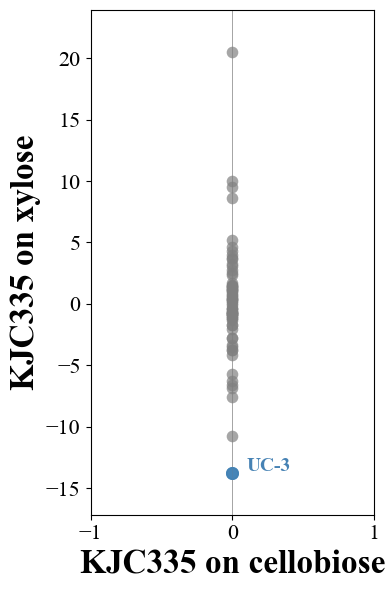

In [5]:
base_condition = 'pentose_sugar_1:del_hpt_ins_xylAB_cb'
diff_condition = 'pentose_sugar_1:del_hpt_ins_xylAB_xyl'

dict_colors = {'UC-3': 'steelblue'}

ax, df_dima_pentose2 = plot_dima(ica_data, 
                            base_condition, 
                            diff_condition, 
                            threshold=5,
                            fdr=0.1,
                            table=True,
                            scatter_kwargs = {'alpha':0.8, 's':70},
                            )

labels_of_interest = list() #any labels that I would like to keep
for t in ax.texts:
    if t.get_text() not in labels_of_interest:
        t.remove()

for imod, row in df_dima_pentose2.iterrows():
    ax.text(row[0] + 0.1, row[1]+0.1,
            imod, fontsize=14, fontweight='bold', color=dict_colors[imod])
    ax.scatter(row[0], row[1], color=dict_colors[imod], alpha=0.8, s=70, zorder=10)

# # set x and y labels
ax.set_xlabel(f'KJC335 on cellobiose', fontdict={'weight':'bold', 'size':24})
ax.set_ylabel(f'KJC335 on xylose', fontdict={'weight':'bold', 'size':24})
# ax.set_ylabel(f'42$^o$C MTC with cellulose', fontdict={'weight':'bold', 'size':20})

# # tick sizes
ax.tick_params(labelsize=16)

# # Get current figure object and modify its size
fig = plt.gcf() 
fig.set_size_inches(4, 6)


plt.tight_layout()

#save plot
# plt.savefig('./results_characterize_imodulons/dima_cb_xyl_kjc335.png', transparent=True, pad_inches=0.01, dpi=300, format='png')

plt.show()

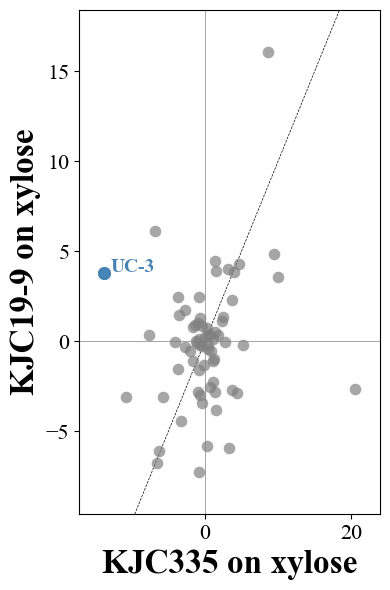

In [6]:
base_condition = 'pentose_sugar_1:del_hpt_ins_xylAB_xyl'
diff_condition = 'pentose_sugar_1:evo_xyl_del_hpt_ins_xylAB_xyl'

dict_colors = {'UC-3': 'steelblue'}

ax, df_dima_pentose1_ev_xyl = plot_dima(ica_data, 
                            base_condition, 
                            diff_condition, 
                            threshold=5,
                            fdr=0.1,
                            table=True,
                            scatter_kwargs = {'alpha':0.8, 's':70},
                            )


labels_of_interest = list() #any labels that I would like to keep
for t in ax.texts:
    if t.get_text() not in labels_of_interest:
        t.remove()

for imod, row in df_dima_pentose1_ev_xyl.iterrows():
    ax.text(row[0] + 0.9, row[1]+0.05,
            imod, fontsize=14, fontweight='bold', color=dict_colors[imod])

    ax.scatter(row[0], row[1], color=dict_colors[imod], alpha=0.8, s=70, zorder=10)


# # also label and color Pentose
# target_x = 8.633229
# target_y = 16.065934

# ax.scatter(target_x, target_y, color='lightblue')
# ax.text(8.6 + 0.9, 16+0.05,
#             'Pentose', fontsize=12, color="lightblue")

    

# # set x and y labels
ax.set_xlabel(f'KJC335 on xylose', fontdict={'weight':'bold', 'size':24})
ax.set_ylabel(f'KJC19-9 on xylose', fontdict={'weight':'bold', 'size':24})
# ax.set_ylabel(f'42$^o$C MTC with cellulose', fontdict={'weight':'bold', 'size':20})

# # tick sizes
ax.tick_params(labelsize=16)

# # Get current figure object and modify its size
fig = plt.gcf() 
fig.set_size_inches(4, 6)


plt.tight_layout()

#save plot
# plt.savefig('./results_characterize_imodulons/dima_cb_kjc335_xyl_kjc19-9.png', transparent=True, pad_inches=0.01, dpi=300, format='png')

plt.show()

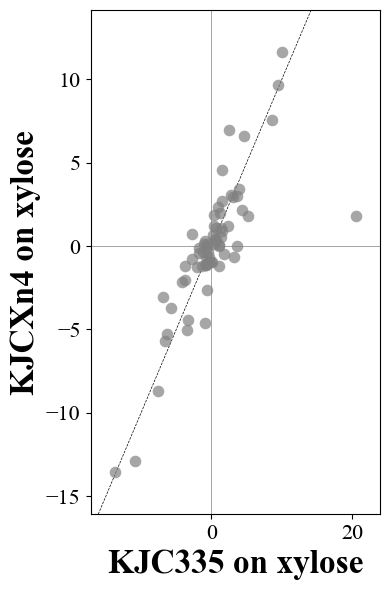

In [7]:
base_condition = 'pentose_sugar_1:del_hpt_ins_xylAB_xyl'
diff_condition = 'pentose_sugar_1:evo_xyl_xyla_del_hpt_ins_xylAB_xyl'

dict_colors = {'UC-3': 'steelblue', 'TetR_0692': 'orange', 'UC-12': 'orange', 'UC-3': 'orange'}

ax, df_dima_pentose1_ev_xyl_xyla = plot_dima(ica_data, 
                            base_condition, 
                            diff_condition, 
                            threshold=5,
                            fdr=0.1,
                            table=True,
                            scatter_kwargs = {'alpha':0.8, 's':70},
                            )


labels_of_interest = list() #any labels that I would like to keep
for t in ax.texts:
    if t.get_text() not in labels_of_interest:
        t.remove()

for imod, row in df_dima_pentose1_ev_xyl_xyla.iterrows():
    ax.text(row[0] + 0.05, row[1]+0.05,
            imod, fontsize=14, fontweight='bold', color=dict_colors[imod])

    ax.scatter(row[0], row[1], color=dict_colors[imod], alpha=0.8, s=70, zorder=10)

# # set x and y labels
ax.set_xlabel(f'KJC335 on xylose', fontdict={'weight':'bold', 'size':24})
ax.set_ylabel(f'KJCXn4 on xylose', fontdict={'weight':'bold', 'size':24})
# ax.set_ylabel(f'42$^o$C MTC with cellulose', fontdict={'weight':'bold', 'size':20})

# # tick sizes
ax.tick_params(labelsize=16)

# # Get current figure object and modify its size
fig = plt.gcf() 
fig.set_size_inches(4, 6)


plt.tight_layout()

#save plot
# plt.savefig('./results_characterize_imodulons/dima_cb_kjc335_xyl_kjcxn4.png', transparent=True, pad_inches=0.01, dpi=300, format='png')

plt.show()

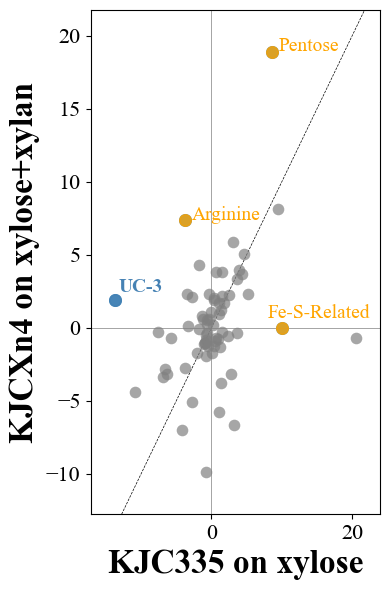

In [8]:
base_condition = 'pentose_sugar_1:del_hpt_ins_xylAB_xyl'
diff_condition = 'pentose_sugar_1:evo_xyl_xyla_del_hpt_ins_xylAB_xyl_xyla'

dict_colors = {'UC-3': 'steelblue', 'Arginine': 'orange', 'Pentose': 'orange', 'Fe-S-Related': 'orange'}

ax, df_dima_pentose1_ev_xyl_xyla = plot_dima(ica_data, 
                            base_condition, 
                            diff_condition, 
                            threshold=5,
                            fdr=0.1,
                            table=True,
                            scatter_kwargs = {'alpha':0.8, 's':70},
                            )


labels_of_interest = list() #any labels that I would like to keep
for t in ax.texts:
    if t.get_text() not in labels_of_interest:
        t.remove()

for imod, row in df_dima_pentose1_ev_xyl_xyla.iterrows():
    if imod in ['UC-3']:
            ax.text(row[0] + 0.5, row[1]+0.5,
                    imod, fontsize=14, fontweight='bold', color=dict_colors[imod])

    elif imod in ['Fe-S-Related']:
            ax.text(row[0]-2., row[1]+0.7,
                    imod, fontsize=14, color=dict_colors[imod])
    else:
        ax.text(row[0] + 0.9, row[1]+0.05,
                imod, fontsize=14, color=dict_colors[imod])

    ax.scatter(row[0], row[1], color=dict_colors[imod], alpha=0.8, s=70, zorder=10)

# # set x and y labels
ax.set_xlabel(f'KJC335 on xylose', fontdict={'weight':'bold', 'size':24})
ax.set_ylabel(f'KJCXn4 on xylose+xylan', fontdict={'weight':'bold', 'size':24})
# ax.set_ylabel(f'42$^o$C MTC with cellulose', fontdict={'weight':'bold', 'size':20})

# # tick sizes
ax.tick_params(labelsize=16)

# # Get current figure object and modify its size
fig = plt.gcf() 
fig.set_size_inches(4, 6)


plt.tight_layout()

#save plot
# plt.savefig('./results_characterize_imodulons/dima_cb_kjc335_xyl_xyla_kjcxn4.png', transparent=True, pad_inches=0.01, dpi=300, format='png')

plt.show()

### IMs of interest

#### UC-3

In [ ]:
imod_of_interest = 'UC-3'
df_genes_uc3 = ica_data.view_imodulon(imod_of_interest).sort_values(by='gene_weight', ascending=False)
df_genes_uc3.head()


,gene_weight,gene_name,accession,old_locus_tag,start,end,strand,gene_product,COG,uniprot,operon,GO_MF,GO_BP,InterPro,PFAMs,regulator
Clo1313_0528,0.442747,RS02705,CP002416.1,NaN,582762,582959,+,4Fe-4S ferredoxin iron-sulfur binding domain-c...,Energy production and conversion,UPI00003C8DDF,Op336,NaN,NaN,4Fe4S_Fe-S-bd;4Fe4S_Fe_S_CS;Fe-S_Ferredoxin;,Fer4;Fer4_4;Fer4_6,NaN
Clo1313_0529,0.388427,RS02710,CP002416.1,NaN,582994,583584,+,hypothetical protein,Energy production and conversion,UPI00017E27B5,Op336,NaN,NaN,4Fe4S_Fe-S-bd;,Fer4_5,NaN
Clo1313_0632,-0.117200,RS03235,CP002416.1,NaN,719356,719559,+,EmrB/QacA family drug resistance transporter,No COG annotation,UPI000038FC7A,Op412,NaN,NaN,NaN,NaN,NaN
Clo1313_0826,-0.157000,Clo1313_0826,CP002416.1,NaN,953401,953499,+,hypothetical protein,No COG annotation,UPI0001F3298E,Op552,NaN,NaN,NaN,NaN,NaN


##### plot the gene weight plot for the IM of interest

In [11]:
# assign a new category for plot_gene_weights
df_genes_uc3['category'] = ''
unclassified_genes = list()
for gene, col in df_genes_uc3.iterrows():
    if gene in ['Clo1313_1964', 'Clo1313_1963', 'Clo1313_0528', 'Clo1313_0705', 'Clo1313_0706']:
        df_genes_uc3.loc[gene, 'category'] = 'selected' #differentially regulated in literature
    # elif gene in ['Clo1313_0054']:
    #     df_genes_uc3.loc[gene, 'category'] = 'probably_cellulosome'
    else: #'Clo1313_0729', 'Clo1313_1702', 'Clo1313_1703', 'Clo1313_1704', 'Clo1313_0055'
        df_genes_uc3.loc[gene, 'category'] = 'not_selected' #not differentially regulated in literature
        unclassified_genes.append(gene)
df_genes_uc3.loc[unclassified_genes]

,gene_weight,gene_name,accession,old_locus_tag,start,end,strand,gene_product,COG,uniprot,operon,GO_MF,GO_BP,InterPro,PFAMs,regulator,category


Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


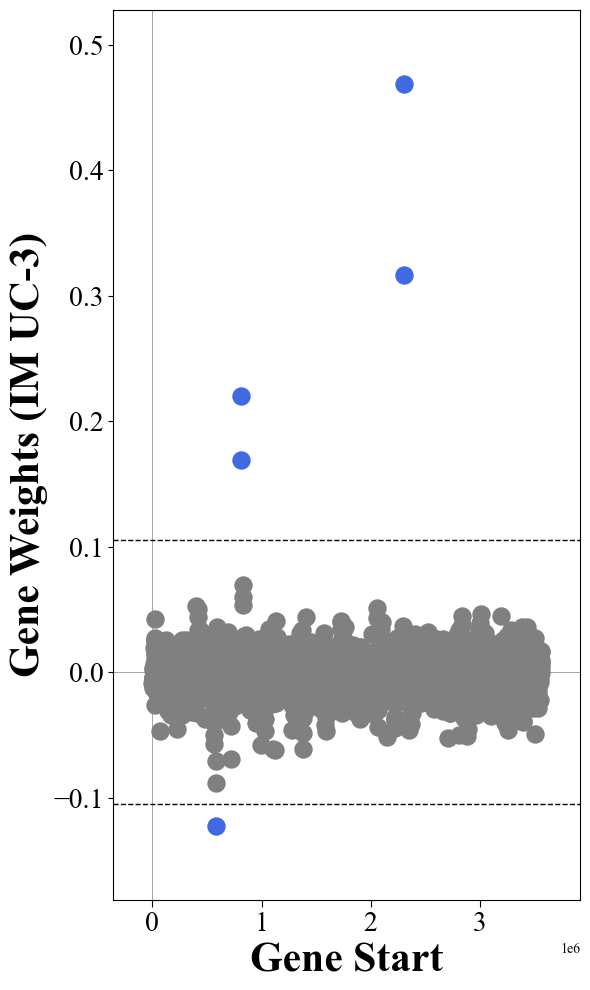

In [12]:
# Example: list of genes you want to highlight
selected_genes = df_genes_uc3.loc[df_genes_uc3.category=='selected'].index.to_list()
# prob_cellulosome_genes = df_genes_gh9.loc[df_genes_gh9.category=='probably_cellulosome'].index.to_list()
not_selected = df_genes_uc3.loc[df_genes_uc3.category=='not_selected'].index.to_list()

# Create a group label per gene
groups = pd.Series('not_in_imod', index=ica_data.M.index.to_list())
groups.loc[selected_genes] = 'selected'
# groups.loc[prob_cellulosome_genes] = 'prob_selected'
groups.loc[not_selected] = 'not_selected'


# Define colors: grey for others, red for selected genes
colors = {
    'not_in_imod': 'grey',
    'not_selected': 'darkorange',
    # "prob_selected": "steelblue",
    "selected": "royalblue",

}

ax = plot_gene_weights(ica_data, imod_of_interest, by='start', 
                        groups=groups,     # which genes are in which group
                        colors=colors,     # color mapping
                        scatter_kwargs={'s':150},
                        show_labels=True, adjust_labels=True, legend=False)
                    
ax.set_ylabel(f'Gene Weights (IM {imod_of_interest})', fontdict={'weight':'bold', 'size':30})
ax.set_xlabel('Gene Start', fontdict={'weight':'bold', 'size':30})

ax.tick_params(axis='y', labelsize=20)
ax.tick_params(axis='x', labelsize=20, size=5)

# ax.set_xticks([])

labels_of_interest = [] #any labels that I would like to keep

for t in ax.texts:
    if t.get_text() not in labels_of_interest:
        t.remove()

# Get current figure object and modify its size
fig = plt.gcf() 
fig.set_size_inches(6, 10)

plt.tight_layout()

#save plot
# plt.savefig('./results_characterize_imodulons/gene_wts_uc3_im.png', transparent=True, pad_inches=0.01, dpi=300, format='png')

plt.show()

##### expression changes of the genes of interest (pucG, RS03650, ferredoxin, ferredoxin binding protein) for conditions/projects of interest

/var/folders/8c/yy8ts7rn59j58vl5_l6jgcmd1lvs3b/T/ipykernel_3051/1112898510.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['KJC335_cb', 'KJC335_xyl', 'KJC19-9_xyl'], size=20, weight='bold', rotation=90)
/var/folders/8c/yy8ts7rn59j58vl5_l6jgcmd1lvs3b/T/ipykernel_3051/1112898510.py:44: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


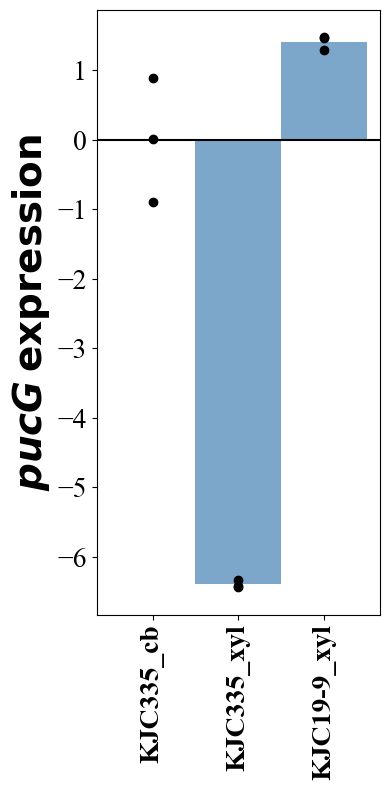

/var/folders/8c/yy8ts7rn59j58vl5_l6jgcmd1lvs3b/T/ipykernel_3051/1112898510.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['KJC335_cb', 'KJC335_xyl', 'KJC19-9_xyl'], size=20, weight='bold', rotation=90)
/var/folders/8c/yy8ts7rn59j58vl5_l6jgcmd1lvs3b/T/ipykernel_3051/1112898510.py:44: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


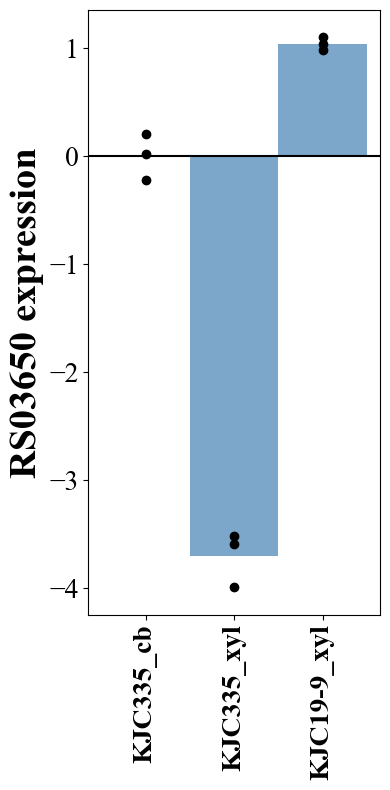

/var/folders/8c/yy8ts7rn59j58vl5_l6jgcmd1lvs3b/T/ipykernel_3051/1112898510.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['KJC335_cb', 'KJC335_xyl', 'KJC19-9_xyl'], size=20, weight='bold', rotation=90)
/var/folders/8c/yy8ts7rn59j58vl5_l6jgcmd1lvs3b/T/ipykernel_3051/1112898510.py:44: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


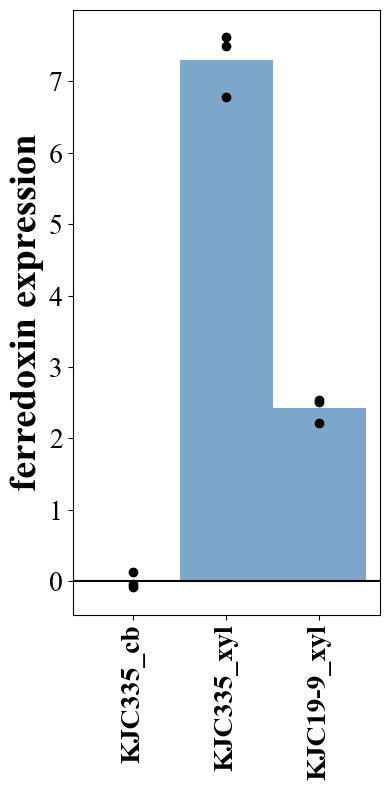

/var/folders/8c/yy8ts7rn59j58vl5_l6jgcmd1lvs3b/T/ipykernel_3051/1112898510.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['KJC335_cb', 'KJC335_xyl', 'KJC19-9_xyl'], size=20, weight='bold', rotation=90)
/var/folders/8c/yy8ts7rn59j58vl5_l6jgcmd1lvs3b/T/ipykernel_3051/1112898510.py:44: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


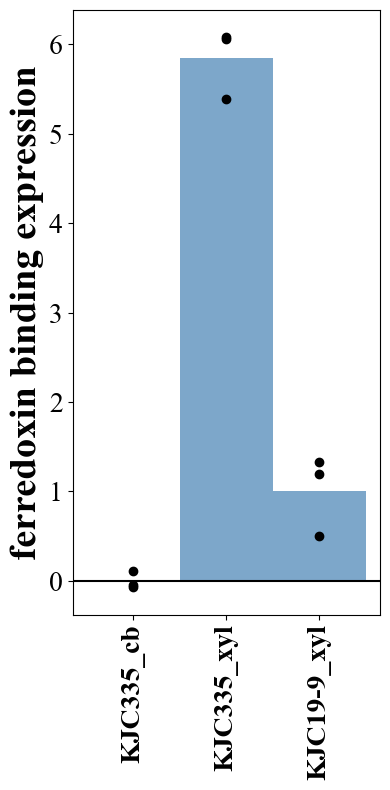

In [16]:
proj_interested = 'pentose_sugar_1'
conditions = ['del_hpt_ins_xylAB_cb', 'del_hpt_ins_xylAB_xyl', 'evo_xyl_del_hpt_ins_xylAB_xyl']

dict_gene_names = {'Clo1313_1964': 'pucG', 'Clo1313_0705': 'RS03650', 'Clo1313_0528':'ferredoxin', 'Clo1313_0529': 'ferredoxin binding'}
for gene_of_interest in ['Clo1313_1964', 'Clo1313_0705', 'Clo1313_0528', 'Clo1313_0529']:

    fig, ax = plt.subplots(1, 1, figsize=(4, 8), constrained_layout=True)

    # compare expression conditions for expression
    for cond in conditions:
        full_name_proj = f'{proj_interested}:{cond}'
        exp_of_interest = df_metadata.loc[df_metadata.full_name == full_name_proj]
        df_expression_gene = df_expression.loc[gene_of_interest, exp_of_interest.index.to_list()]
        mean_exp = np.mean(df_expression_gene.values)

        ax.bar(
            cond,
            mean_exp,
            color=['steelblue', 'salmon'], 
            alpha=0.7,
            width=1,
            linewidth=0.1,
            align='center',
            zorder=0.1,
            label=cond,
        )
        ax.scatter([cond] * len(df_expression_gene), df_expression_gene.values, color="black", zorder=3)

    # # add a horizontal line
    ax.axhline(y=0, color='k')

    # change tick parameters and labels
    ax.tick_params(axis='y', labelsize=20)
    ylab = dict_gene_names[gene_of_interest]
    if ylab=='pucG':
        ax.set_ylabel('$\mathbfit{pucG}\:\mathbf{expression}$', fontdict={'weight':'bold', 'size':28})
    else:
        ax.set_ylabel(f'{ylab} expression', fontdict={'weight':'bold', 'size':28})
    
    ax.set_xticklabels(['KJC335_cb', 'KJC335_xyl', 'KJC19-9_xyl'], size=20, weight='bold', rotation=90)

    # save the plot
    # plt.savefig('./results_characterize_imodulons/pucg_exp_change_pent_sugar_1.png', transparent=True, pad_inches=0.01, dpi=300, format='png')
    plt.tight_layout()

    plt.show()

#### Pentose

In [18]:
imod_of_interest = 'Pentose'

df_genes_pentose = ica_data.view_imodulon(imod_of_interest).sort_values(by='gene_weight', ascending=False)
df_genes_pentose


,gene_weight,gene_name,accession,old_locus_tag,start,end,strand,gene_product,COG,uniprot,operon,GO_MF,GO_BP,InterPro,PFAMs,regulator
Clo1313_0075,0.305044,RS00390,CP002416.1,NaN,80581,81522,+,Transketolase domain-containing protein,Carbohydrate transport and metabolism,UPI00003C8F24,Op55,NaN,NaN,PDH/Transketolase;THDP-binding;Transketo_C/PFO...,Transket_pyr;Transketolase_C,NaN
Clo1313_0076,0.298403,RS00395,CP002416.1,NaN,81603,82646,+,Alcohol dehydrogenase GroES domain protein,Energy production and conversion,UPI00003C8F23,Op56,NaN,NaN,ADH-like_C;ADH-like_N;ADH_Zn_CS;GroES-like_sf;...,ADH_N;ADH_zinc_N,NaN
Clo1313_0074,0.298033,RS00385,CP002416.1,NaN,79748,80584,+,Transketolase domain-containing protein,Carbohydrate transport and metabolism,UPI00003C8F25,Op55,NaN,NaN,THDP-binding;Transketolase_CS;Transketolase_N;,Transketolase_N,NaN
Clo1313_0077,0.268390,RS00400,CP002416.1,NaN,82829,83947,+,hypothetical protein,Carbohydrate transport and metabolism,UPI00003C8F22,Op57,NaN,NaN,Bact_Solute-Bind_Prot2;Peripla_BP_I;SBP_2_dom;,Peripla_BP_4,NaN
Clo1313_0073,0.261559,glpK,CP002416.1,NaN,78258,79742,+,Carbohydrate kinase%2C FGGY-like protein,Carbohydrate transport and metabolism,UPI000038FAE5,Op55,NaN,NaN,ATPase_NBD;Carb_kinase_FGGY;Carb_kinase_FGGY_C...,FGGY_C;FGGY_N,NaN
Clo1313_0078,0.261252,RS00405,CP002416.1,NaN,83949,85436,+,ABC transporter related protein,Carbohydrate transport and metabolism,UPI0001B1EFD0,Op57,NaN,NaN,AAA+_ATPase;ABC_carbohydrate_import_ATPase;ABC...,ABC_tran,NaN
Clo1313_0080,0.250836,RS00415,CP002416.1,NaN,86440,87054,+,Phosphoglycerate mutase,Carbohydrate transport and metabolism,UPI00017E17C0,Op57,NaN,NaN,His_Pase_superF_clade-1;His_PPase_superfam;PG/...,His_Phos_1,NaN
Clo1313_0079,0.248201,RS00410,CP002416.1,NaN,85455,86438,+,inner-membrane translocator,Carbohydrate transport and metabolism,UPI00003C8F20,Op57,NaN,NaN,ABC_transp_permease;,BPD_transp_2,NaN


#### Arginine

In [19]:
imod_of_interest = 'Arginine'

df_genes_arg = ica_data.view_imodulon(imod_of_interest).sort_values(by='gene_weight', ascending=False)
df_genes_arg

,gene_weight,gene_name,accession,old_locus_tag,start,end,strand,gene_product,COG,uniprot,operon,GO_MF,GO_BP,InterPro,PFAMs,regulator
Clo1313_2561,0.211209,argF,CP002416.1,NaN,3004235,3005158,+,ornithine carbamoyltransferase,Amino acid transport and metabolism,UPI000038FB9A,Op1734,NaN,NaN,Asp/Orn_carbamoyltranf_P-bd;Asp/Orn_carbamoylT...,OTCace;OTCace_N,NaN
Clo1313_2560,0.209553,carB,CP002416.1,NaN,3000997,3004200,+,carbamoyl-phosphate synthase%2C large subunit,Nucleotide transport and metabolism,UPI0000532219,Op1734,ATP binding; carbamoyl-phosphate synthase (amm...,'de novo' UMP biosynthetic process; glutamine ...,ATP-grasp;ATP_grasp_subdomain_1;CarbamoylP_syn...,CPSase_L_D2;CPSase_L_D3;MGS,NaN
Clo1313_2562,0.202979,RS13010,CP002416.1,NaN,3005171,3005647,+,GCN5-related N-acetyltransferase,Amino acid transport and metabolism,UPI000038FB99,Op1734,NaN,NaN,Acyl_CoA_acyltransferase;Bact_Acetyltransf;GNA...,Acetyltransf_1,NaN
Clo1313_2559,0.195597,carA,CP002416.1,NaN,2999899,3000963,+,carbamoyl-phosphate synthase%2C small subunit,Nucleotide transport and metabolism,UPI00017E2E2B,Op1734,ATP binding; carbamoyl-phosphate synthase (glu...,'de novo' pyrimidine nucleobase biosynthetic p...,Anth_synth/Amidotransfase;CarbamoylP_synth_ssu...,CPSase_sm_chain;GATase,NaN
Clo1313_2558,0.194147,RS12990,CP002416.1,NaN,2998477,2999679,+,acetylornithine and succinylornithine aminotra...,Amino acid transport and metabolism,UPI00017E2E2C,Op1734,NaN,NaN,AcOrn/SuccOrn_fam;Aminotrans_3;Aminotrans_3_PP...,Aminotran_3,NaN
Clo1313_2556,0.184098,argB,CP002416.1,NaN,2996314,2997228,+,acetylglutamate kinase,Amino acid transport and metabolism,UPI0000537247,Op1732,acetylglutamate kinase activity; ATP binding,L-arginine biosynthetic process via ornithine,AceGlu_kinase-like_sf;AcgluKinase_fam;ArgB;Asp...,AA_kinase,NaN
Clo1313_2555,0.182813,RS12975,CP002416.1,NaN,2995209,2996249,+,N-acetyl-gamma-glutamyl-phosphate reductase,Amino acid transport and metabolism,UPI0001B1EFDE,Op1732,NaN,NaN,AGPR;AGPR_AS;AGPR_dimerisation_dom;AGPR_type-1...,Semialdhyde_dh;Semialdhyde_dhC,NaN
Clo1313_1254,-0.094916,RS06370,CP002416.1,NaN,1485599,1486477,-,dihydrodipicolinate synthase,Amino acid transport and metabolism,UPI0000531BF6,Op866,NaN,NaN,Aldolase_TIM;DapA;DapA-like;Schiff_base-form_a...,DHDPS,NaN
Clo1313_1252,-0.098455,RS06360,CP002416.1,NaN,1484300,1484758,-,amino acid-binding ACT domain protein,Amino acid transport and metabolism,UPI00003C8DFF,Op866,NaN,NaN,ACT-like_dom_sf;,ACT;ACT_7,NaN


#### Fe-S-Related

In [20]:
imod_of_interest = 'Fe-S-Related'
df_genes_fes = ica_data.view_imodulon(imod_of_interest).sort_values(by='gene_weight', ascending=False)
df_genes_fes


,gene_weight,gene_name,accession,old_locus_tag,start,end,strand,gene_product,COG,uniprot,operon,GO_MF,GO_BP,InterPro,PFAMs,regulator
Clo1313_0528,0.442747,RS02705,CP002416.1,NaN,582762,582959,+,4Fe-4S ferredoxin iron-sulfur binding domain-c...,Energy production and conversion,UPI00003C8DDF,Op336,NaN,NaN,4Fe4S_Fe-S-bd;4Fe4S_Fe_S_CS;Fe-S_Ferredoxin;,Fer4;Fer4_4;Fer4_6,NaN
Clo1313_0529,0.388427,RS02710,CP002416.1,NaN,582994,583584,+,hypothetical protein,Energy production and conversion,UPI00017E27B5,Op336,NaN,NaN,4Fe4S_Fe-S-bd;,Fer4_5,NaN
Clo1313_0632,-0.117200,RS03235,CP002416.1,NaN,719356,719559,+,EmrB/QacA family drug resistance transporter,No COG annotation,UPI000038FC7A,Op412,NaN,NaN,NaN,NaN,NaN
Clo1313_0826,-0.157000,Clo1313_0826,CP002416.1,NaN,953401,953499,+,hypothetical protein,No COG annotation,UPI0001F3298E,Op552,NaN,NaN,NaN,NaN,NaN


# FIN